<a href="https://colab.research.google.com/github/TatianaZiabrova/TatianaZiabrova/blob/main/Practical_task_example_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Импорт библиотек, установка рабочей директории**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

In [ ]:
%matplotlib inline
sns.set()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks

/content/drive/MyDrive/Colab Notebooks


In [ ]:
!pwd

/content/drive/MyDrive/Colab Notebooks


# **Загрузка датасета**

Исследуем датасет, включающий в себя данные о сне, образе жизни и здоровье респондентов.

Загрузим датасет в программу с помощью функции pd.read_csv().

In [ ]:
data_sleep = pd.read_csv('sleep_health_and_lifestyle_dataset.csv')
data_sleep

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


Датасет содержит 374 записей и 13 колонок параметров.
Данные, доступные для анализа:
Пол, возраст респондента, профессия,средняя продолжительность сна, качество сна, уровень физической активности, уровень стресса, ИМТ (категориально), кровяное давление, пульс, количество шагов в день, наличие заболеваний, связанных со сном.

In [ ]:
data_sleep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


# **Описательная статистика**

Исследуем описательную статистику датасета с помощью метода `describe()`

In [ ]:
data_sleep.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


Отдельно изучим данные о возрасте респондентов. Узнаем среднее, медиану, минимальное и максимальное значение, стандартное отклонение, квартили.

In [ ]:
print('Среднее значение возраста респондентов:', data_sleep['Age'].mean())
print('Медиана возраста респондентов:', data_sleep['Age'].median())
print('Минимальное значение возраста респондентов:', data_sleep['Age'].min())
print('Максимальное значение возраста респондентов:', data_sleep['Age'].max())
print('Стандартное отклонение значения возраста респондентов:', data_sleep['Age'].std())
print('Квартили значений возраста респондентов: ', *data_sleep['Age'].quantile([0.25, 0.5, 0.75]))

Среднее значение возраста респондентов: 42.18449197860963
Медиана возраста респондентов: 43.0
Минимальное значение возраста респондентов: 27
Максимальное значение возраста респондентов: 59
Стандартное отклонение значения возраста респондентов: 8.67313346554724
Квартили значений возраста респондентов:  35.25 43.0 50.0


Рассмотрим, какие уникальные значения принимают параметры возраста, профессии, качества сна.

In [ ]:
print(data_sleep['Age'].unique())
print(data_sleep['Occupation'].unique())
print(data_sleep['Quality of Sleep'].unique())

[27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 48 49 50 51 52
 53 54 55 56 57 58 59]
['Software Engineer' 'Doctor' 'Sales Representative' 'Teacher' 'Nurse'
 'Engineer' 'Accountant' 'Scientist' 'Lawyer' 'Salesperson' 'Manager']
[6 4 7 5 8 9]


Количество уникальных значений для этих параметров узнаем через функцию `len()`, которая находит количество элементов в списке:

In [ ]:
print(len(data_sleep['Age'].unique()))
print(len(data_sleep['Occupation'].unique()))
print(len(data_sleep['Quality of Sleep'].unique()))

31
11
6


Изучим, как распределено количество респондентов по этим параметрам.

In [ ]:
print(data_sleep['Age'].sort_values().value_counts(sort=False))

Age
27     1
28     5
29    13
30    13
31    18
32    17
33    13
34     2
35    12
36    12
37    20
38    20
39    15
40     4
41    12
42     9
43    34
44    30
45    14
48     3
49    11
50    20
51     8
52     9
53    17
54     7
55     2
56     2
57     9
58     6
59    16
Name: count, dtype: int64


Больше всего 43-летних респондентов, меньше всего 27-летних

In [ ]:
print(data_sleep['Occupation'].sort_values().value_counts(sort=False))

Occupation
Accountant              37
Doctor                  71
Engineer                63
Lawyer                  47
Manager                  1
Nurse                   73
Sales Representative     2
Salesperson             32
Scientist                4
Software Engineer        4
Teacher                 40
Name: count, dtype: int64


Больше всего респондентов медсестер/медбратьев, меньше всего респондентов менеджеров.

In [ ]:
print(data_sleep['Quality of Sleep'].sort_values().value_counts(sort=False))

Quality of Sleep
4      5
5      7
6    105
7     77
8    109
9     71
Name: count, dtype: int64


Изучим также распределение данных о средней продолжительности сна респондентов.

In [ ]:
print(data_sleep['Sleep Duration'].sort_values().value_counts(sort=False))

Sleep Duration
5.8     2
5.9     4
6.0    31
6.1    25
6.2    12
6.3    13
6.4     9
6.5    26
6.6    20
6.7     5
6.8     5
6.9     3
7.1    19
7.2    36
7.3    14
7.4     5
7.5     5
7.6    10
7.7    24
7.8    28
7.9     7
8.0    13
8.1    15
8.2    11
8.3     5
8.4    14
8.5    13
Name: count, dtype: int64


Сохраним в отдельную таблицу данные о респондентах возрастом старше 40.

In [ ]:
data_sleep_over_40 = data_sleep[data_sleep['Age'] >= 40]
data_sleep_over_40

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
161,162,Female,40,Accountant,7.2,8,55,6,Normal Weight,119/77,73,7300,NaN
162,163,Female,40,Accountant,7.2,8,55,6,Normal Weight,119/77,73,7300,NaN
163,164,Male,40,Lawyer,7.9,8,90,5,Normal,130/85,68,8000,NaN
164,165,Male,40,Lawyer,7.9,8,90,5,Normal,130/85,68,8000,NaN
165,166,Male,41,Lawyer,7.6,8,90,5,Normal,130/85,70,8000,Insomnia
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


Для респондентов старше 40 найдем среднюю продолжительность сна, округлим ее до десятых.

In [ ]:
print('Средняя продолжительность сна для респондентов старше 40:',
      round(data_sleep_over_40['Sleep Duration'].mean(), 1))

Средняя продолжительность сна для респондентов старше 40: 7.2


Сохраним в файл эти данные.

In [ ]:
data_sleep_over_40.to_csv('data_sleep_over_40.csv', index=False)

Сгруппируем данные по полу респондентов и сравним их показатели сна и стресса.

In [ ]:
grouped_gender_duration = data_sleep.groupby('Gender').aggregate({'Sleep Duration': 'mean'})
grouped_gender_quality = data_sleep.groupby('Gender').aggregate({'Quality of Sleep': 'mean'})
grouped_gender_stress = data_sleep.groupby('Gender').aggregate({'Stress Level': 'mean'})

print(grouped_gender_duration)
print()
print(grouped_gender_quality)
print()
print(grouped_gender_stress)

        Sleep Duration
Gender                
Female        7.229730
Male          7.036508

        Quality of Sleep
Gender                  
Female          7.664865
Male            6.968254

        Stress Level
Gender              
Female      4.675676
Male        6.079365


Можно предположить, что в среднем женщины испытывают меньше стресса, чем мужчины.

# **Визуализация данных**

In [ ]:
data_sleep

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


Построим гистограммы для распределений возраста и продолжительности сна.

Найдем разницу между максимальным и минимальным возрастом в наших данных.

In [ ]:
print(data_sleep['Age'].max() - data_sleep['Age'].min())

32


Разница составляет 32, тогда зададим параметр bins так, чтобы каждый столбец покрывал целое число лет. Если bins = 8, то каждый столбец покрывает 4 года.

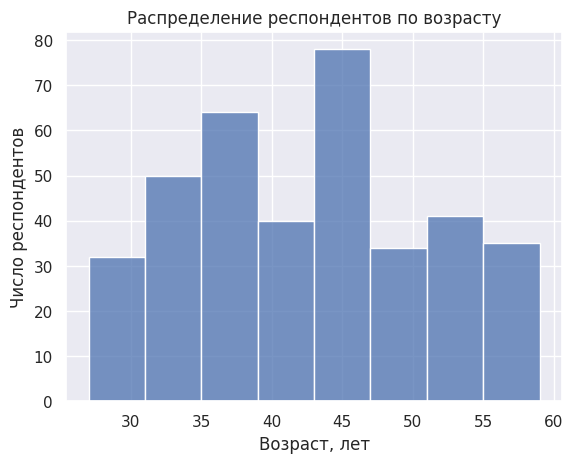

In [ ]:
# Метод dropna() позволяет игнорировать пустые значения в таблице данных.
age_hist = sns.histplot(data=data_sleep['Age'].dropna(), bins=8)
# Задаем заголовок графика
plt.title('Распределение респондентов по возрасту')
# Подписываем оси графика
plt.xlabel('Возраст, лет')
plt.ylabel('Число респондентов')
# Корректно выводим график на экран
plt.show()

То же самое выполним для параметра продолжительности сна респондентов.

In [ ]:
print(data_sleep['Sleep Duration'].max() - data_sleep['Sleep Duration'].min())

2.7


Разница составляет 2.7, тогда параметр bins установим на 9, чтобы каждый столбец покрывал 0.3 часа.

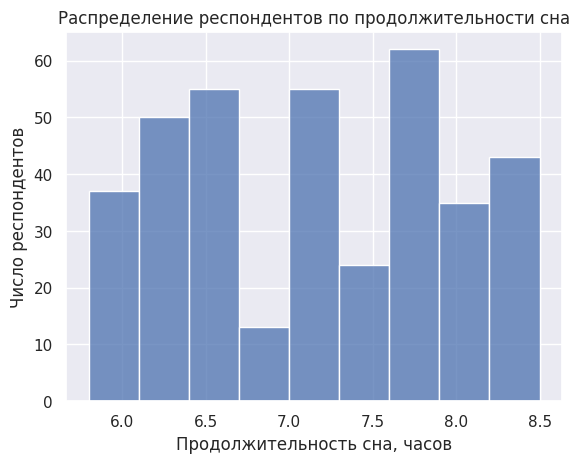

In [ ]:
# Метод dropna() позволяет игнорировать пустые значения в таблице данных.
duration_hist = sns.histplot(data=data_sleep['Sleep Duration'].dropna(), bins=9)
# Задаем заголовок графика
plt.title('Распределение респондентов по продолжительности сна')
# Подписываем оси графика
plt.xlabel('Продолжительность сна, часов')
plt.ylabel('Число респондентов')
# Корректно выводим график на экран
plt.show()

Построим боксплоты для изучения различных параметров.

/tmp/ipykernel_463/1168852240.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  duration_occupation_box = sns.boxplot(x='Occupation', y='Sleep Duration',
/tmp/ipykernel_463/1168852240.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  duration_occupation_box.set_xticklabels(duration_occupation_box.get_xticklabels(),


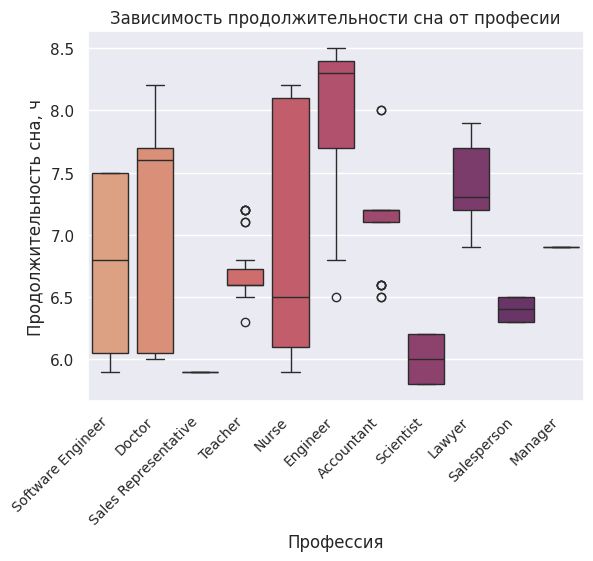

In [ ]:
#Параметром palette меняем цвет боксплотов
duration_occupation_box = sns.boxplot(x='Occupation', y='Sleep Duration',
                                      data=data_sleep, palette='flare')
plt.title("Зависимость продолжительности сна от професии")
plt.xlabel("Профессия")
plt.ylabel("Продолжительность сна, ч")
#Для лучшей видимости повернем подписи по оси х на 45 градусов и уменьшим их размер
duration_occupation_box.set_xticklabels(duration_occupation_box.get_xticklabels(),
                                        rotation=45, fontsize=10, ha='right')
plt.show()

Можно выделить профессии, представители которых спят в среднем больше остальных - инженеры и адвокаты. Меньше всех спят учителя и ученые.

/tmp/ipykernel_463/1682714462.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  duration_quality_box = sns.boxplot(x='Quality of Sleep', y='Sleep Duration',


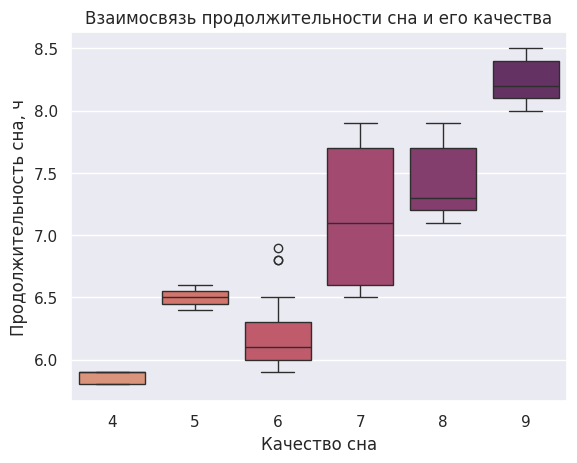

In [ ]:
#Параметром palette меняем цвет боксплотов
duration_quality_box = sns.boxplot(x='Quality of Sleep', y='Sleep Duration',
                                      data=data_sleep, palette='flare')
plt.title("Взаимосвязь продолжительности сна и его качества")
plt.xlabel("Качество сна")
plt.ylabel("Продолжительность сна, ч")
# Сохраним график на гугл-диск
plt.savefig('duration_quality_box.png', dpi=400)
plt.show()

Наблюдаем явную взаимосвязь качества сна и его продолжительности.

# **Проверка статистических гипотез**

Изучим, как отличаются различные параметры у людей без расстройств сна и с расстройствами сна

Создадим две выборки

In [ ]:
# Выборка людей с расстройством сна
# Попадут все люди, у которых в параметре 'Sleep Disorder' записано хоть что-нибудь
data_sleep_pos = data_sleep[data_sleep['Sleep Disorder'].notna()]

# Выборка людей без расстройства сна
# Попадут все люди, у которых в параметре 'Sleep Disorder' запись пустая
data_sleep_neg = data_sleep[data_sleep['Sleep Disorder'].isna()]

In [ ]:
data_sleep_pos

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
5,6,Male,28,Software Engineer,5.9,4,30,8,Obese,140/90,85,3000,Insomnia
6,7,Male,29,Teacher,6.3,6,40,7,Obese,140/90,82,3500,Insomnia
16,17,Female,29,Nurse,6.5,5,40,7,Normal Weight,132/87,80,4000,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [ ]:
data_sleep_neg

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
7,8,Male,29,Doctor,7.8,7,75,6,Normal,120/80,70,8000,NaN
8,9,Male,29,Doctor,7.8,7,75,6,Normal,120/80,70,8000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,342,Female,56,Doctor,8.2,9,90,3,Normal Weight,118/75,65,10000,NaN
342,343,Female,56,Doctor,8.2,9,90,3,Normal Weight,118/75,65,10000,NaN
343,344,Female,57,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,NaN
358,359,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,NaN


Изучим, как в этих выборках соотносятся параметры Quality of Sleep, Sleep Duration и Physical Activity Level

Для начала проверим, распределены ли выборки по этим параметрам нормально, будем использовать критерий Шапиро-Уилка `stats.shapiro()`

In [ ]:
print('Выборка респондентов с расстройствами сна')
print('p-value критерия Шапиро-Уилка для параметра качества сна:',
      stats.shapiro(data_sleep_pos['Quality of Sleep'])[1])
print('p-value критерия Шапиро-Уилка для параметра длительности сна:',
      stats.shapiro(data_sleep_pos['Sleep Duration'])[1])
print('p-value критерия Шапиро-Уилка для уровня физической активности:',
      stats.shapiro(data_sleep_pos['Physical Activity Level'])[1])

print('Выборка респондентов без расстройств сна')
print('p-value критерия Шапиро-Уилка для параметра качества сна:',
      stats.shapiro(data_sleep_neg['Quality of Sleep'])[1])
print('p-value критерия Шапиро-Уилка для параметра длительности сна:',
      stats.shapiro(data_sleep_neg['Sleep Duration'])[1])
print('p-value критерия Шапиро-Уилка для уровня физической активности:',
      stats.shapiro(data_sleep_neg['Physical Activity Level'])[1])

Выборка респондентов с расстройствами сна
p-value критерия Шапиро-Уилка для параметра качества сна: 5.5651429985026436e-11
p-value критерия Шапиро-Уилка для параметра длительности сна: 4.933100056241084e-12
p-value критерия Шапиро-Уилка для уровня физической активности: 6.34468104677137e-12
Выборка респондентов без расстройств сна
p-value критерия Шапиро-Уилка для параметра качества сна: 8.70541663652957e-14
p-value критерия Шапиро-Уилка для параметра длительности сна: 2.9214427023010202e-09
p-value критерия Шапиро-Уилка для уровня физической активности: 2.5775606271046037e-12


Все выборки распределены ненормально, они несвязанные, для их сравнения будем использовать непараметрический критерий - U-критерий Манна-Уитни `stats.mannwhitneyu()`

ДОПОЛНИТЕЛЬНО

Следующий код позволяет проверить на нормальность выборку по всем имеющимся числовым параметрам

In [ ]:
#Создадим список с именами всех интересующих нас колонок
num_columns = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level',
               'Stress Level', 'Heart Rate', 'Daily Steps']

#Создадим цикл, перебирающий все указанные нами колонки по очереди
for col in num_columns:
    # Для каждой колонки вычисляем значение критерия Шапиро-Уилка
    shapiro_test = stats.shapiro(data_sleep[col])
    #В зависимости от значения p-value, полученного из критерия, выводим результат на экран
    if shapiro_test[1] > 0.05:
        print('Данные в колонке', col.upper(), 'распределены НОРМАЛЬНО, p-value =', shapiro_test[1])
    else:
         print('Данные в колонке', col.upper(), 'распределены НЕНОРМАЛЬНО, p-value =', shapiro_test[1])

    print()


Данные в колонке AGE распределены НЕНОРМАЛЬНО, p-value = 7.416838675908542e-09

Данные в колонке SLEEP DURATION распределены НЕНОРМАЛЬНО, p-value = 1.2678283000990912e-11

Данные в колонке QUALITY OF SLEEP распределены НЕНОРМАЛЬНО, p-value = 1.8815294645817528e-15

Данные в колонке PHYSICAL ACTIVITY LEVEL распределены НЕНОРМАЛЬНО, p-value = 5.1763566827592826e-15

Данные в колонке STRESS LEVEL распределены НЕНОРМАЛЬНО, p-value = 1.1126085088535512e-15

Данные в колонке HEART RATE распределены НЕНОРМАЛЬНО, p-value = 2.6849518855928184e-16

Данные в колонке DAILY STEPS распределены НЕНОРМАЛЬНО, p-value = 1.6531796290397034e-11



Критерии для несвязанных (независимых) выборок
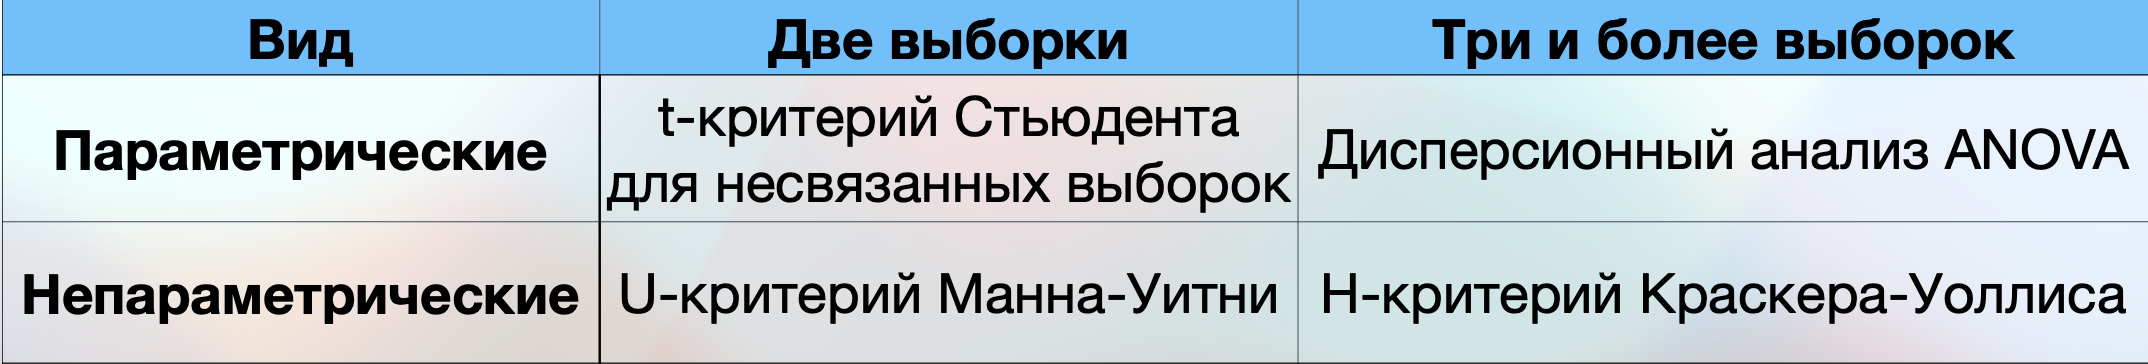

Эти критерии соответствуют следующим функциям в Python:

*   t-критерий Стьюдента для несвязанных выборок - `stats.ttest_ind()`
*   U-критерий Манна-Уитни - `stats.mannwhitneyu()`
* Дисперсионный анализ ANOVA - `stats.f_oneway()`
* H-критерий Краскера-Уоллиса - `stats.kruskal()`



Критерии для связанных (зависимых) выборок
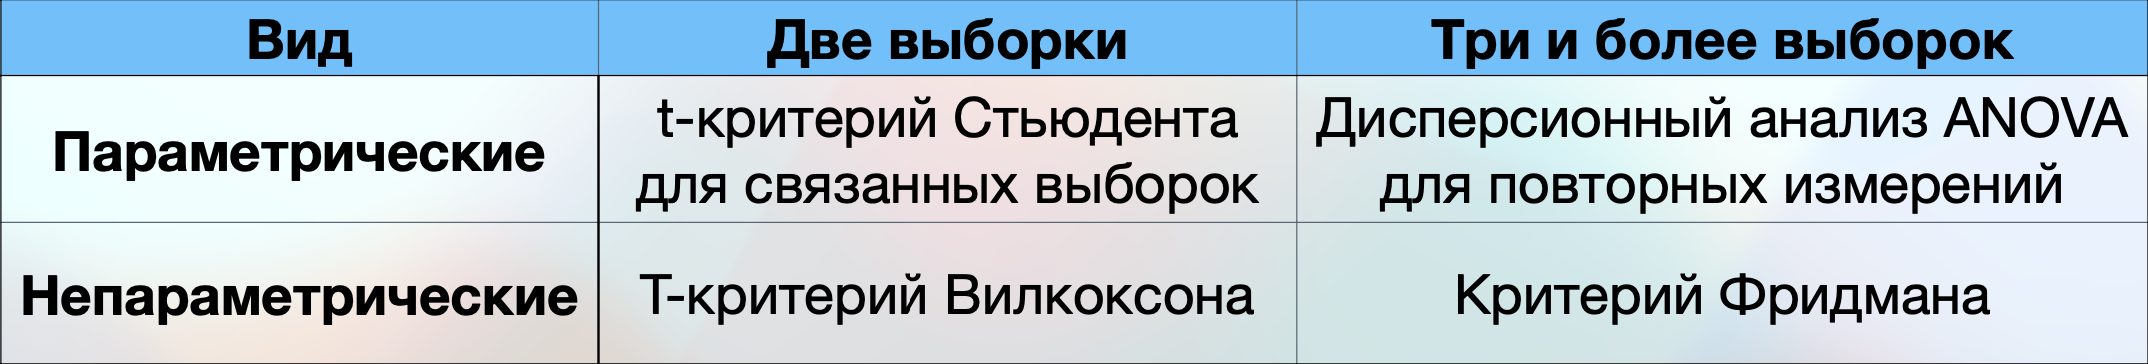

Эти критерии соответствуют следующим функциям в Python:

*   t-критерий Стьюдента для связанных выборок - `stats.ttest_rel()`
*   T-критерий Вилкоксона - `stats.wilcoxon()`
*   Дисперсионный анализ ANOVA для повторных измерений - функция `AnovaRM()` из библиотеки `statsmodels.stats.anova`
*   Критерий Фридмана - `stats.friedmanchisquare()`



Во всех тестах значение p-value хранится во второй ячейке списка, который получается в результате выполнения функции. То есть, например, чтобы вывести на экран значение p-value, полученное после применения критерия Стьюдента, нужно написать:

`print(stats.ttest_ind(data_1, data_2)[1])`

Значение самого критерия находится в ячейке с индексом [0]

Применим U-критерий Манна-Уитни для сравнения параметров двух выборок

In [ ]:
print('p-value U-критерия Манна-Уитни при сравнении выборок респондентов с наличием и отсутствием расстройств сна:')
print('По параметру качества сна:',
      stats.mannwhitneyu(data_sleep_pos['Quality of Sleep'], data_sleep_neg['Quality of Sleep'])[1])
print('По параметру длительности сна:',
      stats.mannwhitneyu(data_sleep_pos['Sleep Duration'], data_sleep_neg['Sleep Duration'])[1])
print('По уровню физической активности:',
      stats.mannwhitneyu(data_sleep_pos['Physical Activity Level'], data_sleep_neg['Physical Activity Level'])[1])

p-value U-критерия Манна-Уитни при сравнении выборок респондентов с наличием и отсутствием расстройств сна:
По параметру качества сна: 5.7473470562437014e-09
По параметру длительности сна: 3.6377100238201065e-09
По уровню физической активности: 0.16873691629851428


По параметрам качества и длительности сна данные выборки статистически значимо отличаются. Вполне возможно, что наличие расстройств сна влияет на его длительность и качество

Уровень физической активности у выборок не отличается. Вероятно, наличие или отсутствие расстройств сна существенно не влияет на физическую активность

ДОПОЛНИТЕЛЬНО

Сравнение всех параметров выборок у мужчин и женщин

Сохраним в отдельные переменные данные по мужчинам и женщинам.

In [ ]:
men_data = data_sleep[data_sleep['Gender'] == 'Male']
women_data = data_sleep[data_sleep['Gender'] == 'Female']

Для сравнения этих выборок по различным параметрам будем использовать непараметрический критерий для несвязанных выборок - U-критерий Манна-Уитни.



In [ ]:
#Создадим список с именами всех интересующих нас колонок
num_columns = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level',
               'Stress Level', 'Heart Rate', 'Daily Steps']

#Создадим цикл, перебирающий все указанные нами колонки по очереди
for col in num_columns:
    # Для каждой колонки вычисляем значение критерия Манна-Уитни
    mann_test = stats.mannwhitneyu(men_data[col], women_data[col])
    #В зависимости от значения p-value, полученного из критерия, выводим результат на экран
    if mann_test[1] < 0.05:
        print('Данные по мужчинам и женщинам по параметру', col.upper(),
              'статистически ОТЛИЧАЮТСЯ, p-value =', mann_test[1])
    else:
        print('Данные по мужчинам и женщинам по параметру', col.upper(),
              'статистически НЕ ОТЛИЧАЮТСЯ, p-value =', mann_test[1])
    print()

Данные по мужчинам и женщинам по параметру AGE статистически ОТЛИЧАЮТСЯ, p-value = 8.379659804355159e-30

Данные по мужчинам и женщинам по параметру SLEEP DURATION статистически ОТЛИЧАЮТСЯ, p-value = 0.014440351736077347

Данные по мужчинам и женщинам по параметру QUALITY OF SLEEP статистически ОТЛИЧАЮТСЯ, p-value = 6.047606194925148e-09

Данные по мужчинам и женщинам по параметру PHYSICAL ACTIVITY LEVEL статистически НЕ ОТЛИЧАЮТСЯ, p-value = 0.9934121366661607

Данные по мужчинам и женщинам по параметру STRESS LEVEL статистически ОТЛИЧАЮТСЯ, p-value = 2.292941631469874e-16

Данные по мужчинам и женщинам по параметру HEART RATE статистически ОТЛИЧАЮТСЯ, p-value = 3.5716346931085232e-09

Данные по мужчинам и женщинам по параметру DAILY STEPS статистически НЕ ОТЛИЧАЮТСЯ, p-value = 0.12033645877804568



Видим, что различий нет только по параметрам физической активности и количеству шагов в день, по остальным параметрам есть статистически значимые различия.

ДОПОЛНИТЕЛЬНО

Сравнение всех показателей респондентов в зависимости от их качества сна

Сравним различные показатели респондентов в зависимости от их качества сна.

In [ ]:
#Значения, которые принимает качество сна:
#Отсортируем эти значения для удобства
quality_sorted = np.sort(data_sleep['Quality of Sleep'].unique())
print(quality_sorted)

[4 5 6 7 8 9]


Создадим набор таблиц, содержащих данные, соответствующие разным значениям параметра качества сна.

In [ ]:
# Создадим пустой список, который заполним нашими таблицами
data_quality = []

# Цикл переберет все значения параметра качества сна и сохранит
# в список таблицы данных, соответствующие каждому значению качеству сна
for val in quality_sorted:
    # Выделяем из наших данных те, которые соответствуют определенному качеству сна
    # и сохраняем их в отдельную таблицу
    quality_matrix = data_sleep[data_sleep['Quality of Sleep'] == val]
    # Таблицу добавляем в список
    data_quality.append(quality_matrix)

# Выводим получившийся набор таблиц на экран, проверяем правильность выполнения программы
for matrix in data_quality:
    print(matrix)

    Person ID  Gender  Age            Occupation  Sleep Duration  \
3           4    Male   28  Sales Representative             5.9   
4           5    Male   28  Sales Representative             5.9   
5           6    Male   28     Software Engineer             5.9   
80         81  Female   34             Scientist             5.8   
81         82  Female   34             Scientist             5.8   

    Quality of Sleep  Physical Activity Level  Stress Level BMI Category  \
3                  4                       30             8        Obese   
4                  4                       30             8        Obese   
5                  4                       30             8        Obese   
80                 4                       32             8   Overweight   
81                 4                       32             8   Overweight   

   Blood Pressure  Heart Rate  Daily Steps Sleep Disorder  
3          140/90          85         3000    Sleep Apnea  
4          140

Теперь можем сравнить различные параметры наших данных в зависимости от качества сна.

Сравним параметр продолжительности сна.

Для этого создадим массив с данными о продолжительности сна, разделенными по качеству сна из нашего набора таблиц.

In [ ]:
data_quality_duration = []

for matrix in data_quality:
    data_quality_duration.append(matrix['Sleep Duration'])

data_quality_duration

[3     5.9
 4     5.9
 5     5.9
 80    5.8
 81    5.8
 Name: Sleep Duration, dtype: float64,
 16     6.5
 18     6.5
 30     6.4
 31     6.4
 103    6.6
 105    6.6
 147    6.5
 Name: Sleep Duration, dtype: float64,
 0      6.1
 1      6.2
 2      6.2
 6      6.3
 10     6.1
       ... 
 296    6.1
 297    6.1
 303    6.0
 304    6.1
 305    6.1
 Name: Sleep Duration, Length: 105, dtype: float64,
 7      7.8
 8      7.8
 9      7.8
 11     7.8
 19     7.6
       ... 
 307    6.5
 308    6.6
 309    6.6
 310    6.6
 311    6.6
 Name: Sleep Duration, Length: 77, dtype: float64,
 32     7.9
 50     7.5
 51     7.5
 66     7.2
 84     7.5
       ... 
 214    7.8
 215    7.8
 216    7.8
 217    7.8
 218    7.8
 Name: Sleep Duration, Length: 109, dtype: float64,
 149    8.0
 150    8.0
 276    8.1
 277    8.1
 279    8.3
       ... 
 369    8.1
 370    8.0
 371    8.1
 372    8.1
 373    8.1
 Name: Sleep Duration, Length: 71, dtype: float64]

Применим к нашему массиву критерий Краскера-Уоллиса.

In [ ]:
stats.kruskal(*data_quality_duration)

KruskalResult(statistic=np.float64(314.3261908309626), pvalue=np.float64(8.316927835312366e-66))

Получим, что есть статистически значимые различия для длительности сна при разных значениях качества сна.

Мы это видели и на ранее построенном графике.

/tmp/ipykernel_463/3944104493.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  duration_quality_box = sns.boxplot(x='Quality of Sleep', y='Sleep Duration',


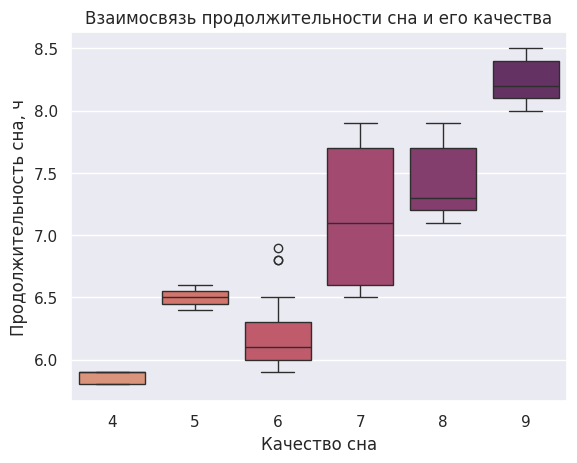

In [ ]:
#Параметром palette меняем цвет боксплотов
duration_quality_box = sns.boxplot(x='Quality of Sleep', y='Sleep Duration',
                                      data=data_sleep, palette='flare')
plt.title("Взаимосвязь продолжительности сна и его качества")
plt.xlabel("Качество сна")
plt.ylabel("Продолжительность сна, ч")
plt.show()

Сделаем такой же тест для параметров возраста, уровня физической активности, уровня стресса и количества шагов в день относительно качества сна.

In [ ]:
params = ['Age', 'Physical Activity Level', 'Stress Level', 'Daily Steps']

data_quality_all = []

#Создадим такие таблицы, разделенные по значениям качества сна со значениями остальных параметров
for par in params:
    data_quality_param = []
    for matrix in data_quality:
        data_quality_param.append(matrix[par])
    data_quality_all.append(data_quality_param)

In [ ]:
#Для каждого параметра проверим критерий Краскера-Уоллиса
for i in range(len(data_quality_all)):
    print('По параметру', params[i].upper(), 'результат критерия Краскера-Уоллиса:',
          stats.kruskal(*data_quality_all[i]))

По параметру AGE результат критерия Краскера-Уоллиса: KruskalResult(statistic=np.float64(176.89013295161342), pvalue=np.float64(2.4689616636188212e-36))
По параметру PHYSICAL ACTIVITY LEVEL результат критерия Краскера-Уоллиса: KruskalResult(statistic=np.float64(51.364420071502686), pvalue=np.float64(7.282498462306259e-10))
По параметру STRESS LEVEL результат критерия Краскера-Уоллиса: KruskalResult(statistic=np.float64(320.9536968766197), pvalue=np.float64(3.12122933749776e-67))
По параметру DAILY STEPS результат критерия Краскера-Уоллиса: KruskalResult(statistic=np.float64(79.03774515278823), pvalue=np.float64(1.333889767021219e-15))


Получим, что есть статистически значимые различия для всех остальных параметров при разных значениях качества сна. То есть, они, видимо, действительно влияют на качество сна.

# **Корреляционный и регрессионный анализ. Построение математической модели**

Построим матрицу корреляций для наших параметров с помощью методов `corr()` и `heatmap()`.

В ячейках матрицы(карты) находятся коэффициенты корреляции Пирсона для соответствующей пары параметров.

Интерепретация силы корреляции в зависимости от величины коэффицента корреляции:

* 0 - 0.3 - слабая корреляция
* 0.3 - 0.7 - средняя корреляция
* 0.7 - 1 - сильная корреляция

То же верно и для отрицательных значений коэффициента

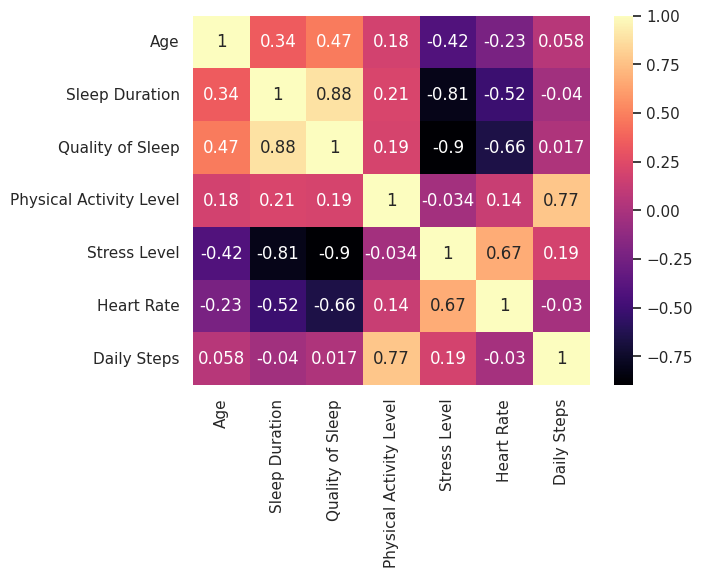

In [ ]:
corr_sleep = data_sleep[['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level',
                         'Stress Level', 'Heart Rate', 'Daily Steps']].corr()
sns.heatmap(corr_sleep, annot=True, cmap='magma')
plt.show()

Сильная корреляция наблюдается для следующих пар переменных:

* Длительность сна и качество сна
* Длительность сна и уровень стресса (отрицательная)
* Качество сна и уровень стресса (отрицательная)
* Уровень физической активности и количество шагов в день

Остальные пары переменных в целом показывают слабую/среднюю корреляционную связь.

Проведем регрессионный анализ и построим модель зависимости показателя качества сна от других параметров.

Для построения регрессионной модели нужно загрузить соответсвующие библиотеки

In [ ]:
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS

Данные будем сохранять в переменные Y (зависимая, качество сна) и X (независимая, все остальные).

К данным нужно добавить константу b0

In [ ]:
X = data_sleep[['Age', 'Sleep Duration', 'Physical Activity Level',
                         'Stress Level', 'Heart Rate', 'Daily Steps']]
Y = data_sleep['Quality of Sleep']

X = sm.add_constant(X, prepend=False)

model = OLS(Y, X)
res = model.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.909
Model:                            OLS   Adj. R-squared:                  0.908
Method:                 Least Squares   F-statistic:                     611.7
Date:                Mon, 02 Mar 2026   Prob (F-statistic):          1.14e-187
Time:                        21:19:30   Log-Likelihood:                -149.01
No. Observations:                 374   AIC:                             312.0
Df Residuals:                     367   BIC:                             339.5
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Age                       

Adj. R-squared - коэффициент детерминации. Показывает, насколько хорошо наша модель объясняет изменчивость данных.

В колонке coef содержатся значения коэффициентов b регрессионной модели.

P>|t| - p-value - используется для оценки значимости коэффициента.

p-value у переменной Physical Activity Level больше 0.05, значит, она не вносит значимого эффекта в модель. Исключим эту переменную.

In [ ]:
X = data_sleep[['Age', 'Sleep Duration',
                         'Stress Level', 'Heart Rate', 'Daily Steps']]
Y = data_sleep['Quality of Sleep']

X = sm.add_constant(X, prepend=False)

model = OLS(Y, X)
res = model.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.909
Model:                            OLS   Adj. R-squared:                  0.908
Method:                 Least Squares   F-statistic:                     735.8
Date:                Mon, 02 Mar 2026   Prob (F-statistic):          4.21e-189
Time:                        21:19:30   Log-Likelihood:                -149.07
No. Observations:                 374   AIC:                             310.1
Df Residuals:                     368   BIC:                             333.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Age                0.0141      0.002      5.

После удаления Physical Activity Level из рассмотрения коэффициент детерминации не изменился. То есть, эта переменная совсем никак не объясняла изменчивость нашей зависимой переменной. Уровень физической активности, согласно нашей модели, не влияет на качество сна.

Построим модель с одной независимой переменной - длительностью сна.

In [ ]:
X = data_sleep['Sleep Duration']
Y = data_sleep['Quality of Sleep']

X = sm.add_constant(X, prepend=False)

model = OLS(Y, X)
res = model.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.780
Model:                            OLS   Adj. R-squared:                  0.779
Method:                 Least Squares   F-statistic:                     1319.
Date:                Mon, 02 Mar 2026   Prob (F-statistic):          2.17e-124
Time:                        21:19:30   Log-Likelihood:                -314.22
No. Observations:                 374   AIC:                             632.4
Df Residuals:                     372   BIC:                             640.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Sleep Duration     1.3287      0.037     36.

Значение коэффициента детерминации уменьшилось, значит, добавление других параметров в модель оправдано.

Продублируем нашу лучшую модель.

In [ ]:
X = data_sleep[['Age', 'Sleep Duration',
                         'Stress Level', 'Heart Rate', 'Daily Steps']]
Y = data_sleep['Quality of Sleep']

X = sm.add_constant(X, prepend=False)

model = OLS(Y, X)
res = model.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.909
Model:                            OLS   Adj. R-squared:                  0.908
Method:                 Least Squares   F-statistic:                     735.8
Date:                Mon, 02 Mar 2026   Prob (F-statistic):          4.21e-189
Time:                        21:19:30   Log-Likelihood:                -149.07
No. Observations:                 374   AIC:                             310.1
Df Residuals:                     368   BIC:                             333.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Age                0.0141      0.002      5.

Заключим, что возраст, продолжительность сна и количество шагов в день положительно влияют на качество сна, а уровень стресса и величина пульса - отрицательно.

Проверим, есть ли между нашими переменными мультиколлинеарность, то есть сильная корреляция между собой. Такое явление может сильно ухудшить качество предсказательной модели. Далеко не факт, что большее число переменных в модели ведет к ее улучшению!

Для этого нам нужен метод `variance_inflation_factor()`

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
# В Х сохраним данные по переменным наилучшей модели и добавим константу
X = data_sleep[['Age', 'Sleep Duration',
                         'Stress Level', 'Heart Rate', 'Daily Steps']]
X = sm.add_constant(X, prepend=False)

#Посчитаем значение параметра VIF
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]


print(vif_data)

          feature         VIF
0             Age    1.267546
1  Sleep Duration    3.078196
2    Stress Level    4.889375
3      Heart Rate    1.954581
4     Daily Steps    1.175834
5           const  790.865566


Значение VIF больше 4 указывает на существенную корреляцию переменной с другими и означает, что ее нужно убрать из модели. Уберем переменную Stress Level.

In [ ]:
# В Х сохраним данные по переменным наилучшей модели и добавим константу
X = data_sleep[['Age', 'Sleep Duration',
                        'Heart Rate', 'Daily Steps']]
X = sm.add_constant(X, prepend=False)

#Посчитаем значение параметра VIF
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]


print(vif_data)

          feature         VIF
0             Age    1.144953
1  Sleep Duration    1.484034
2      Heart Rate    1.372696
3     Daily Steps    1.010495
4           const  765.033835


Значения VIF для остальных переменных меньше 4, можем использовать эти переменные для дальнейшнего построения регрессионной модели.

In [ ]:
X = data_sleep[['Sleep Duration', 'Age', 'Heart Rate', 'Daily Steps']]
Y = data_sleep['Quality of Sleep']

X = sm.add_constant(X, prepend=False)

model = OLS(Y, X)
res = model.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.865
Model:                            OLS   Adj. R-squared:                  0.864
Method:                 Least Squares   F-statistic:                     591.4
Date:                Mon, 02 Mar 2026   Prob (F-statistic):          5.22e-159
Time:                        21:19:30   Log-Likelihood:                -222.88
No. Observations:                 374   AIC:                             455.8
Df Residuals:                     369   BIC:                             475.4
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Sleep Duration     1.0335      0.035     29.

Теперь у переменной Daily Steps получили незначимое значение, так как P>|t|, то есть p-value, больше 0.05. Уберем эту переменную из рассмотрения.

In [ ]:
X = data_sleep[['Sleep Duration', 'Age', 'Heart Rate']]
Y = data_sleep['Quality of Sleep']

X = sm.add_constant(X, prepend=False)

model = OLS(Y, X)
res = model.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.864
Model:                            OLS   Adj. R-squared:                  0.863
Method:                 Least Squares   F-statistic:                     786.2
Date:                Mon, 02 Mar 2026   Prob (F-statistic):          4.18e-160
Time:                        21:19:30   Log-Likelihood:                -223.78
No. Observations:                 374   AIC:                             455.6
Df Residuals:                     370   BIC:                             471.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Sleep Duration     1.0296      0.035     29.

Проверим значение VIF:

In [ ]:
# В Х сохраним данные по переменным наилучшей модели и добавим константу
X = data_sleep[['Age', 'Sleep Duration', 'Heart Rate']]
X = sm.add_constant(X, prepend=False)

#Посчитаем значение параметра VIF
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]


print(vif_data)

          feature         VIF
0             Age    1.138838
1  Sleep Duration    1.474036
2      Heart Rate    1.368541
3           const  730.777885


Получили результирующую модель с тремя переменными: Sleep Duration, Age и Heart Rate. Ее коэффициент детерминации равен 0.863.

Продублируем итоговую модель.

In [ ]:
X = data_sleep[['Sleep Duration', 'Age', 'Heart Rate']]
Y = data_sleep['Quality of Sleep']

X = sm.add_constant(X, prepend=False)

model = OLS(Y, X)
res = model.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.864
Model:                            OLS   Adj. R-squared:                  0.863
Method:                 Least Squares   F-statistic:                     786.2
Date:                Mon, 02 Mar 2026   Prob (F-statistic):          4.18e-160
Time:                        21:19:30   Log-Likelihood:                -223.78
No. Observations:                 374   AIC:                             455.6
Df Residuals:                     370   BIC:                             471.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Sleep Duration     1.0296      0.035     29.

У результирующей модели коэффициент детерминации равен 0.864. Получили, что качество сна можно оценить следующей формулой:

`Quality of sleep = 4.343 + 1.03 * Sleep_Duration + 0.025 * Age - 0.077 * Heart_Rate`

Можно рассчитать свое качество сна по этой формуле.
Если взять Sleep_Duration = 8, Age = 26 и Heart_Rate = 70, получим:



In [ ]:
my_quality = 4.343 + 1.03 * 8 + 0.025 * 26 - 0.077 * 70
print('Согласно введенным данным, ваше качество сна равно', round(my_quality, 1))

Согласно введенным данным, ваше качество сна равно 7.8


Итого, мы построили математическую регрессионную модель наших данных, объясняющую и предсказывающую значения параметра качества сна относительно параметров длительности сна, возраста и сердечного ритма.

ДОПОЛНИТЕЛЬНО

Линейная корреляция по разным переменным с одной независимой переменной в каждом случае.

In [ ]:
params = ['Age', 'Sleep Duration', 'Stress Level', 'Heart Rate', 'Daily Steps']
for par in params:
    X = data_sleep[par]
    Y = data_sleep['Quality of Sleep']

    X = sm.add_constant(X, prepend=False)

    model = OLS(Y, X)
    res = model.fit()
    print('Тестируем параметр', par)
    print()
    print(res.summary())
    print()

Тестируем параметр Age

                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.224
Model:                            OLS   Adj. R-squared:                  0.222
Method:                 Least Squares   F-statistic:                     107.6
Date:                Mon, 02 Mar 2026   Prob (F-statistic):           2.55e-22
Time:                        21:19:30   Log-Likelihood:                -549.89
No. Observations:                 374   AIC:                             1104.
Df Residuals:                     372   BIC:                             1112.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Age            0.0654      0